# Exploratory data analysis: SoLEXS + HEL1OS + GOES

Tune (2025-04-09 … 2026-01-31) and validation (2026-02-01 … 2026-05-31) periods only. The test period is never loaded; the first cell asserts it. Figures are also saved to `docs/figures/eda/`. Findings are summarised in `docs/EDA_SUMMARY.md`.

In [1]:
import os, sys, json
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, ROOT)
import pandas as pd, numpy as np
from IPython.display import Image, display
from src import config, eda
# --- guard: only tune + validation may be used ------------------------------------------------
assert eda.HI == config.period_bounds('val')[1], 'EDA must stop at the end of validation'
assert eda.HI <= config.period_bounds('test')[0], 'EDA window reaches the test period'
qc, m, ev, g, pairs = eda.load_qc(), eda.load_minutes(), eda.load_events(), eda.load_goes(), eda.load_pairs()
eda.check_no_test(qc, m, ev, g)
print('window:', eda.LO, '->', eda.HI, '| days', len(qc), '| minutes', len(m), '| events', len(ev), '| GOES flares', len(g))

window: 2025-04-09 00:00:00+00:00 -> 2026-06-01 00:00:00+00:00 | days 355 | minutes 601919 | events 2516 | GOES flares 3359


## 1. Data coverage

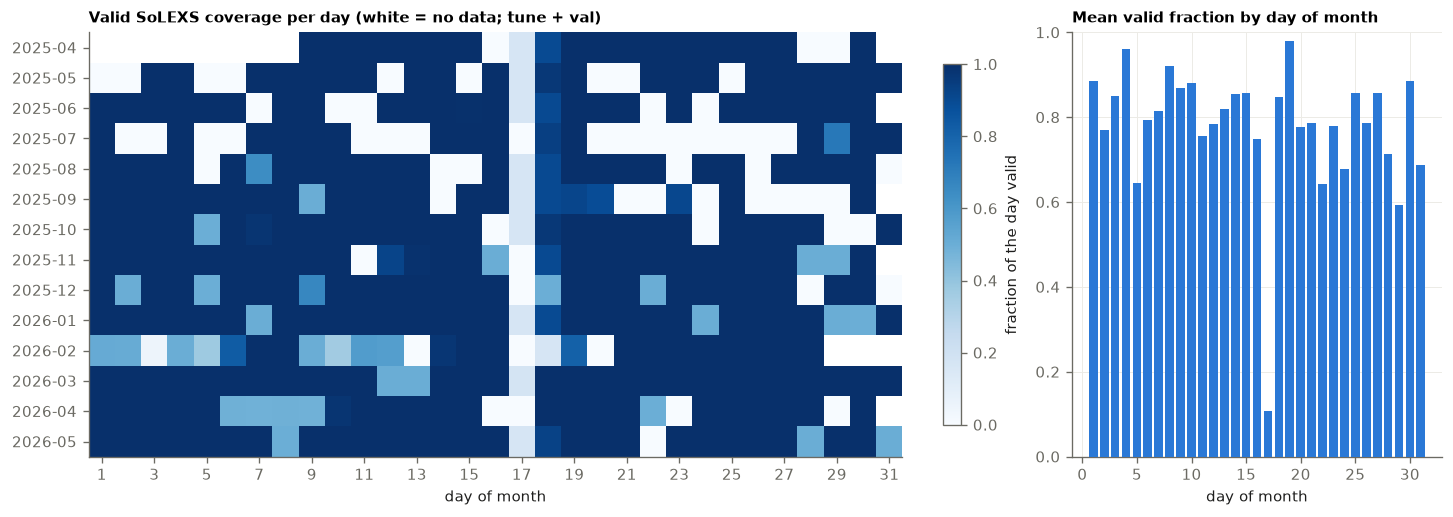

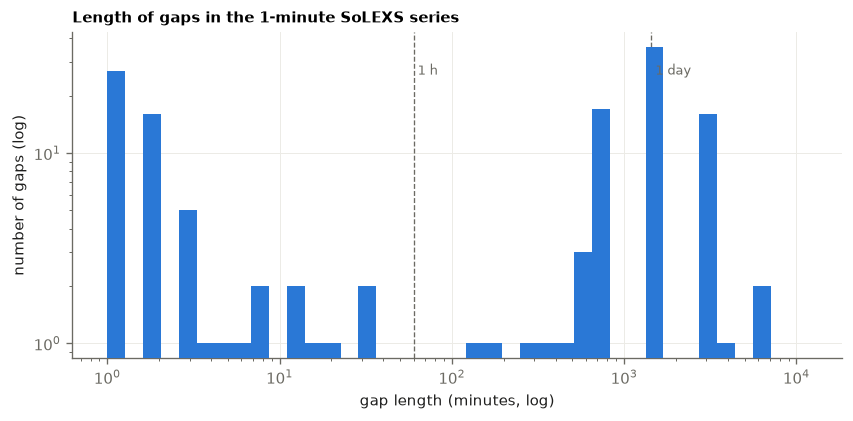

{'days': 418,
 'days_with_folder': 355,
 'days_usable': 331,
 'mean_valid_fraction': 0.7809832978911926,
 'valid_frac_17th': 0.10809275793650792,
 'valid_frac_other': 0.8028161847315493,
 'n_gaps': 140,
 'gaps_le_5min': 50,
 'gaps_ge_1day': 56,
 'longest_gap_days': 8.0,
 'missing_minute_fraction': 0.23663649095642436}

In [2]:
cov = eda.coverage(qc, m); display(Image(cov['fig_calendar'])); display(Image(cov['fig_gaps']))
{k: v for k, v in cov.items() if not k.startswith('fig')}

**Takeaway: coverage.** Of 418 calendar days in tune + val, 355 have a SoLEXS folder and 331 are usable (at least 50 % valid); overall 23.7 % of minutes are missing. The **17th of every month** has only about 11 % valid coverage, against about 80 % on other days: a regular operational pattern, not random loss. There are 140 gaps: 50 last at most 5 minutes and 56 last a day or more (the longest is 8 days). *For modelling:* gaps are never filled; labels need the `ok` flags; partial days are normal and must not be treated as quiet Sun.

## 2. Long-term light curve

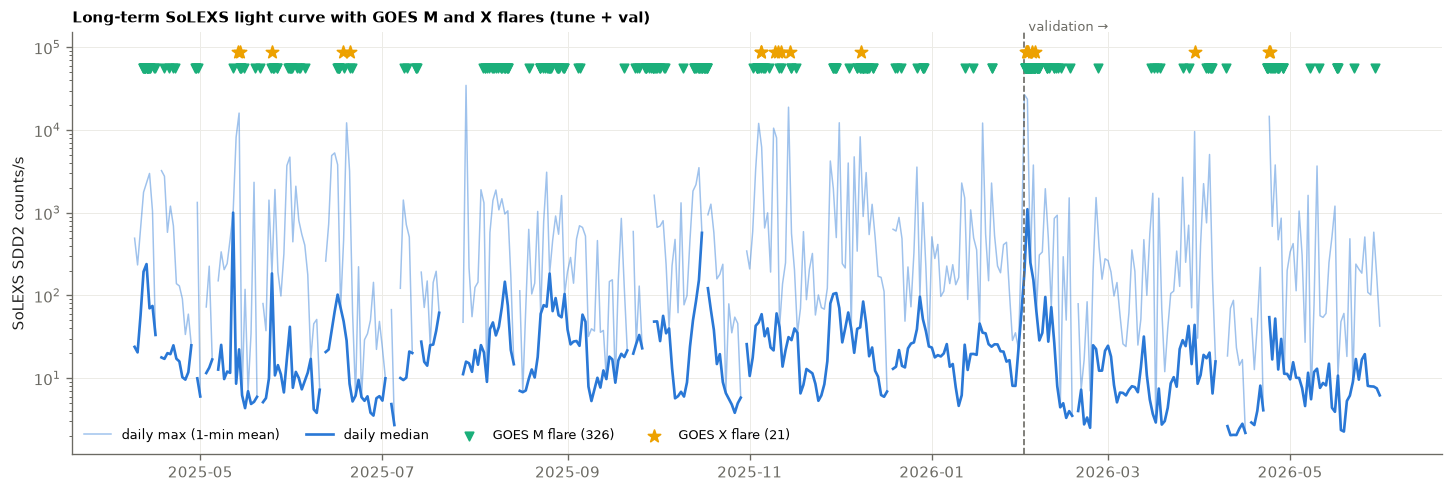

{'median_range': [3.5216666666666665, 90.52833333333324],
 'max_daily_peak': 34637.04761904762,
 'n_M': 326,
 'n_X': 21}

In [3]:
lt = eda.long_term(m, g); display(Image(lt['fig'])); {k: v for k, v in lt.items() if k != 'fig'}

**Takeaway: long-term light curve.** The daily median count rate ranges from about 3.5 to 90 counts/s (5th–95th percentile), while daily peaks reach about 35,000 counts/s, four orders of magnitude. The window holds **326 GOES M and 21 X flares**, clustered in episodes of one to two weeks (active regions crossing the disk). *For modelling:* use log-scaled and background-relative features, and expect strong day-to-day correlation, which is why intervals are bootstrapped by day.

## 3. Solar activity trend

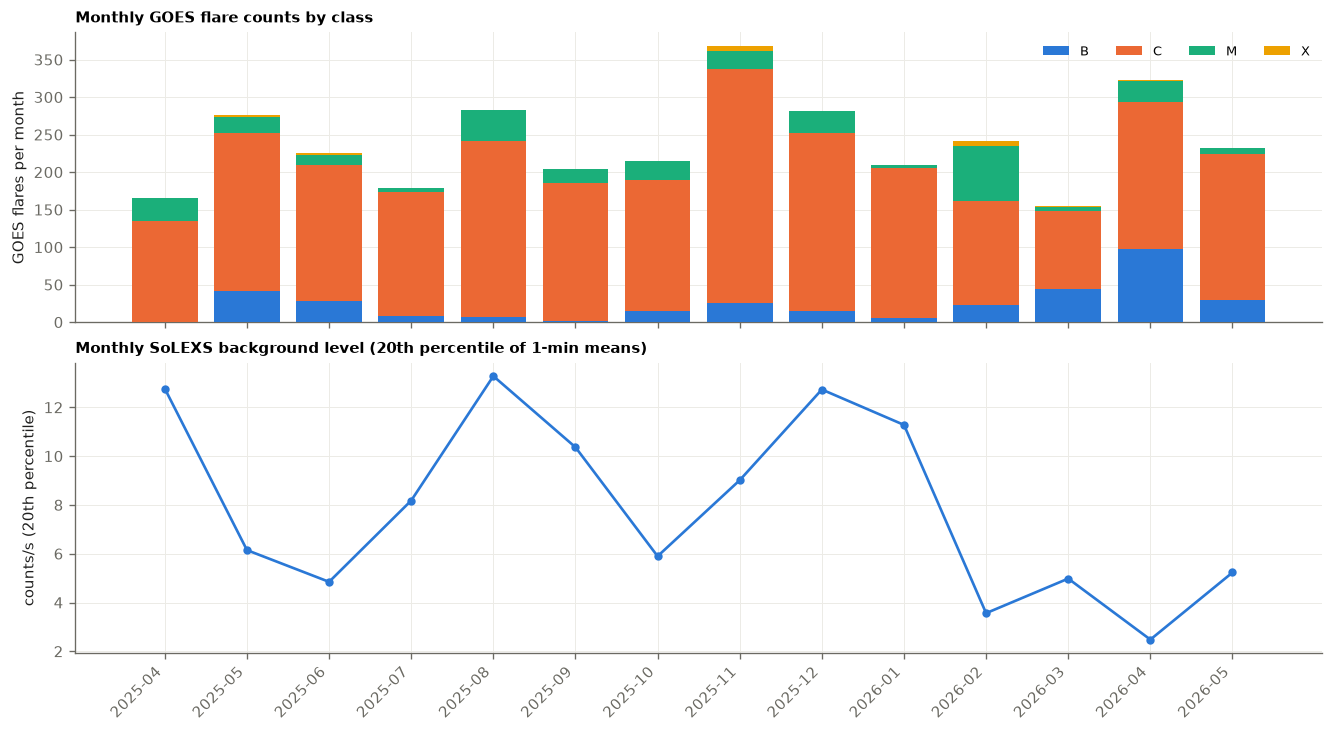

{'bg_first_last': [12.766666666666667, 5.233333333333333],
 'bg_min_max': [2.4833333333333334, 13.283333333333333],
 'flares_per_month_range': [155, 368]}

In [4]:
at = eda.activity_trend(m, g); display(Image(at['fig']))
{k: v for k, v in at.items() if k not in ('fig', 'monthly_counts')}

**Takeaway: activity trend.** GOES lists between 155 and 368 flares per month. The SoLEXS background level (20th percentile of 1-min means) drifts from about 12.8 counts/s (Apr 2025) to about 5.2 counts/s (May 2026), with a range of 2.5–13.3. The data are **not stationary**: the Sun's activity changes over the solar cycle (and instrument effects cannot be excluded). *For modelling:* chronological splits are essential, ratio-to-background features are more stable than raw counts, and models should be checked for drift over time.

## 4. Flare profiles (superposed epoch, aligned on SoLEXS onset)

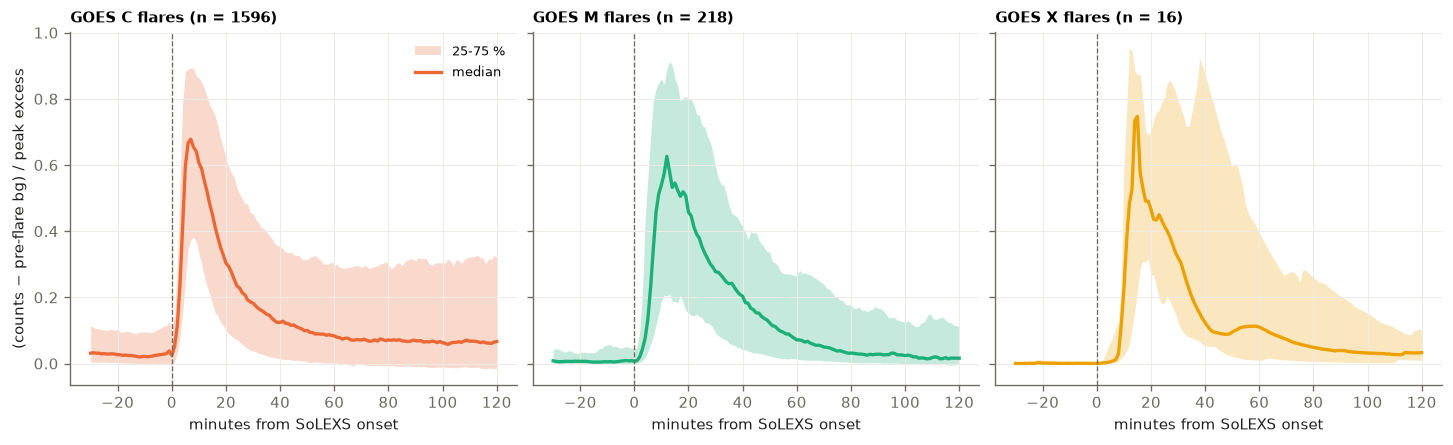

{'C': 1596,
 'C_median_peak_min': 7,
 'C_median_half_decay_min': 7,
 'M': 218,
 'M_median_peak_min': 12,
 'M_median_half_decay_min': 8,
 'X': 16,
 'X_median_peak_min': 15,
 'X_median_half_decay_min': 3}

In [5]:
se = eda.superposed_epoch(m, ev); display(Image(se['fig'])); {k: v for k, v in se.items() if k != 'fig'}

**Takeaway: flare profiles.** Aligned on the SoLEXS onset, the median profile peaks about **7 min (C, n = 1,596), 12 min (M, n = 218) and 15 min (X, n = 16)** after onset: bigger flares rise longer. The median decays to half its excess within about 7–8 minutes after the peak for C and M flares (the X curve, from only 16 flares, is spiky and multi-peaked). The C-class median stays slightly above zero for an hour, because other flares often follow. *For modelling:* a 30-minute horizon covers the rise of most flares; flare clustering (later flares in the tail) is real and partly explains forecast skill.

## 5. Flare statistics

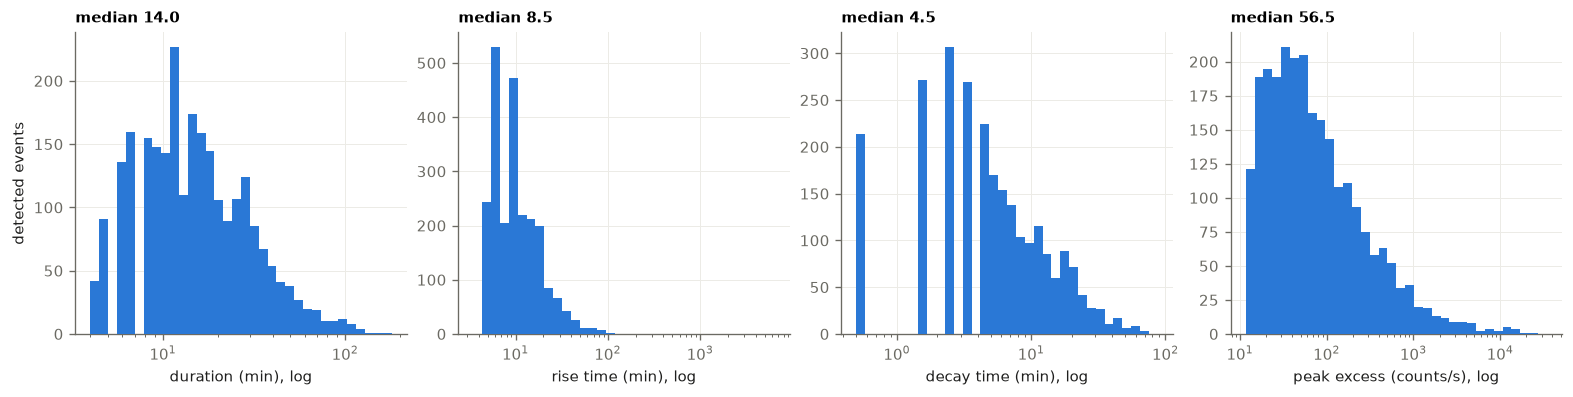

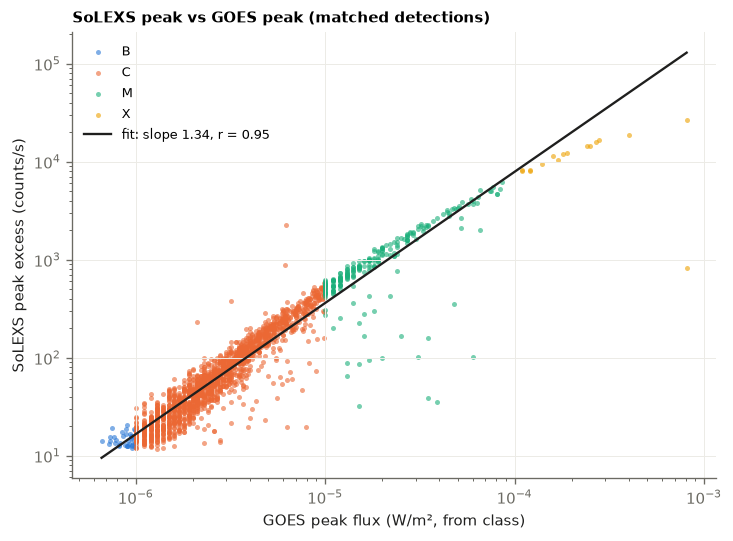

{'n_events': 2516,
 'median_duration_min': 14.0,
 'median_rise_min': 8.5,
 'median_decay_min': 4.5,
 'decay_over_rise_median': 0.5432406519654842,
 'fit_slope': 1.3383411558281506,
 'fit_r': 0.947379714931001,
 'n_matched_fit': 1905}

In [6]:
fs = eda.flare_stats(ev); display(Image(fs['fig_dist'])); display(Image(fs['fig_scatter']))
{k: v for k, v in fs.items() if not k.startswith('fig')}

**Takeaway: flare statistics.** Detected events last a median of 14 min, with a median rise (onset to peak) of 8.5 min and decay (peak to end) of 4.5 min. The decay is short because the end is defined, as in GOES, at half the peak excess, not when the flux is back to background. SoLEXS peak excess grows with GOES peak flux as a power law with slope **1.34** (log-log, r = 0.95, 1,905 matched events). *For modelling:* SoLEXS counts are an excellent but non-linear proxy for GOES class, so log features are appropriate. Classes still come only from GOES, as the project rules require.

## 6. Detector vs GOES

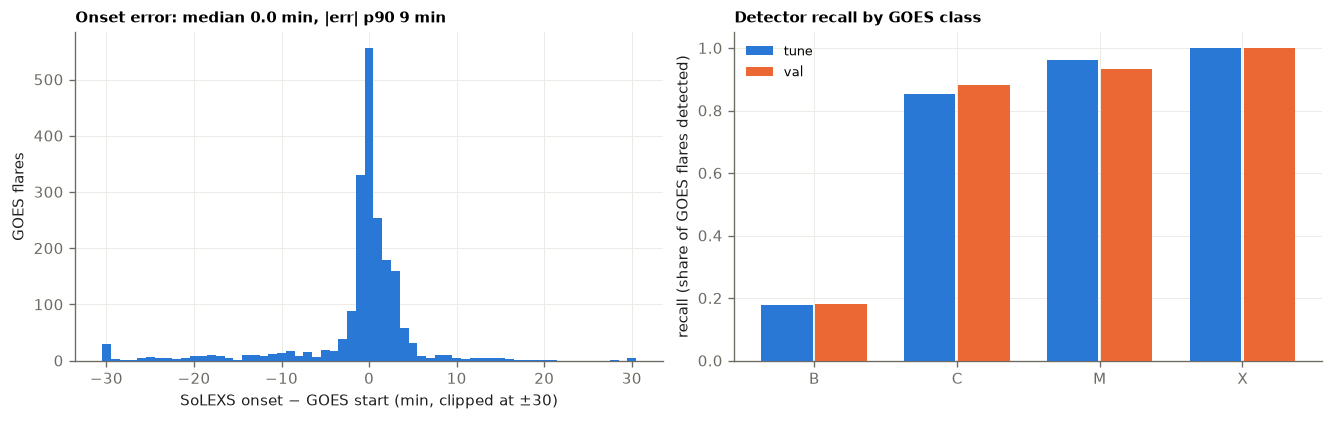

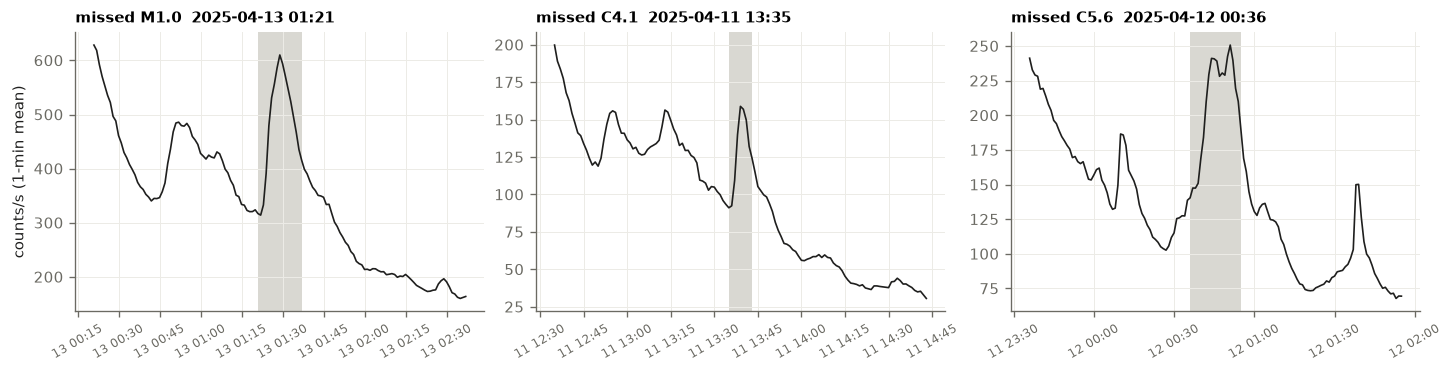

{'onset_err_median': 0.0,
 'onset_abs_p90': 9.0,
 'recall_tune': {'B': 0.176, 'C': 0.854, 'M': 0.963, 'X': 1.0},
 'recall_val': {'B': 0.18, 'C': 0.88, 'M': 0.932, 'X': 1.0},
 'missed_observed_C_M': 292,
 'missed_examples': ['M1.0 2025-04-13 01:21:00+00:00',
  'C4.1 2025-04-11 13:35:00+00:00',
  'C5.6 2025-04-12 00:36:00+00:00']}

In [7]:
dg = eda.detector_vs_goes(m, ev, g, pairs); display(Image(dg['fig'])); display(Image(dg['fig_missed']))
{k: v for k, v in dg.items() if not k.startswith('fig')}

**Takeaway: detector vs GOES.** Onset error versus the GOES start: median **0 min**, 90th percentile of the absolute error 9 min. Recall is C 0.85 / 0.88, M 0.96 / 0.93 and X 1.0 (tune / val), but B only 0.18. **292 GOES C/M flares were missed although SoLEXS was observing**; the examples show small flares sitting on a high or decaying background. *For modelling:* this is why forecast labels are taken from GOES directly (lesson 07). The detector is fine for timing and for the activity flag, not as the source of truth.

## 7. Features (quiet-start rows, target: ≥C flare within 60 min)

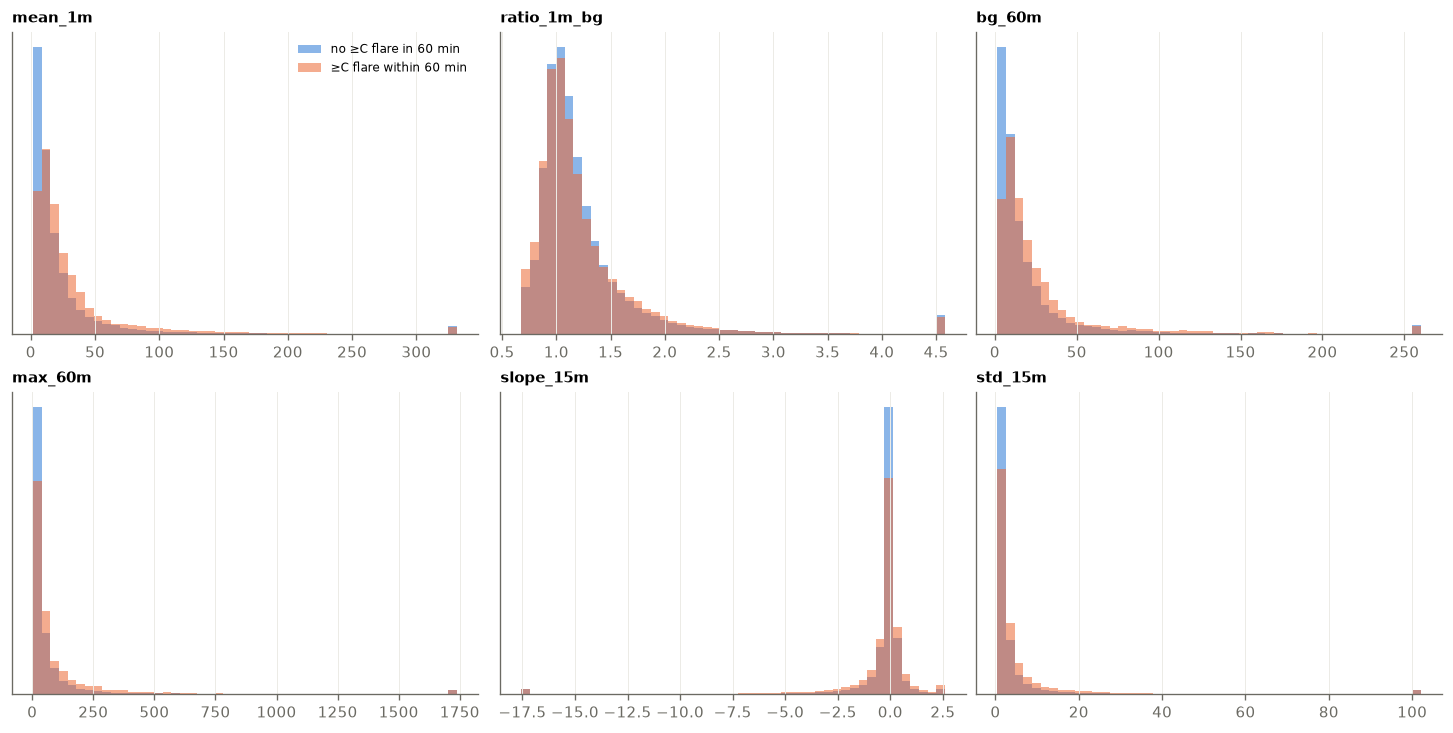

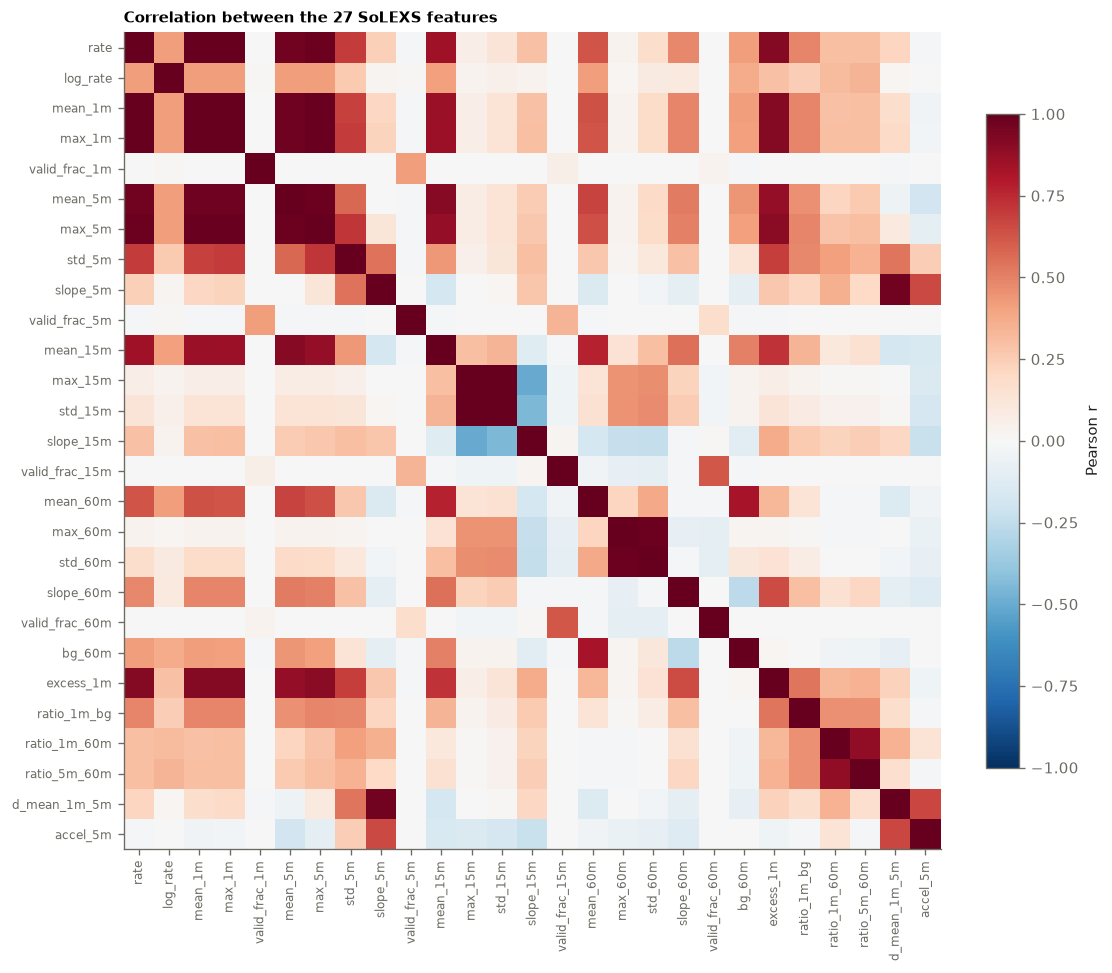

27 SoLEXS features


{'n_quiet_rows_used': 498350,
 'pos_share': 0.2466078057590047,
 'standardised_median_shift': {'mean_1m': 0.017,
  'ratio_1m_bg': -0.0,
  'bg_60m': 0.042,
  'max_60m': 0.002,
  'slope_15m': -0.001,
  'std_15m': 0.001},
 'high_corr_pairs': [('rate', 'max_1m', 0.999),
  ('mean_1m', 'max_1m', 0.999),
  ('rate', 'mean_1m', 0.999),
  ('max_15m', 'std_15m', 0.995),
  ('max_1m', 'max_5m', 0.988),
  ('mean_1m', 'max_5m', 0.986),
  ('rate', 'max_5m', 0.983),
  ('mean_5m', 'max_5m', 0.979),
  ('max_60m', 'std_60m', 0.979),
  ('mean_1m', 'mean_5m', 0.975),
  ('max_1m', 'mean_5m', 0.97),
  ('rate', 'mean_5m', 0.965),
  ('slope_5m', 'd_mean_1m_5m', 0.964),
  ('max_1m', 'excess_1m', 0.916),
  ('rate', 'excess_1m', 0.915),
  ('mean_1m', 'excess_1m', 0.914),
  ('mean_5m', 'mean_15m', 0.912),
  ('max_5m', 'excess_1m', 0.902)]}

In [8]:
cols = None  # all columns
d = eda.load_dataset(); eda.check_no_test(d)
from src import dataset
soft = [c for c in dataset.feature_columns(d) if not c.startswith('hx_') and c != 'hel1os_available']
fe = eda.feature_eda(d, soft); display(Image(fe['fig_dist'])); display(Image(fe['fig_corr']))
print(len(soft), 'SoLEXS features'); {k: v for k, v in fe.items() if not k.startswith('fig')}

**Takeaway: features.** On quiet-start rows, the distributions of single features for rows with a ≥C flare within 60 min versus none overlap almost completely: standardised median shifts are at most 0.04 for the six features shown. No single feature forecasts flares; skill (TSS about 0.2 for ≥C) must come from combinations and from the activity level. **18 feature pairs have |r| > 0.9**; `rate`, `mean_1m` and `max_1m` are practically identical (r = 0.999). *For modelling:* redundancy does not hurt trees but makes logistic-regression coefficients hard to interpret; dropping duplicates is a candidate simplification.

## 8. Label base rates

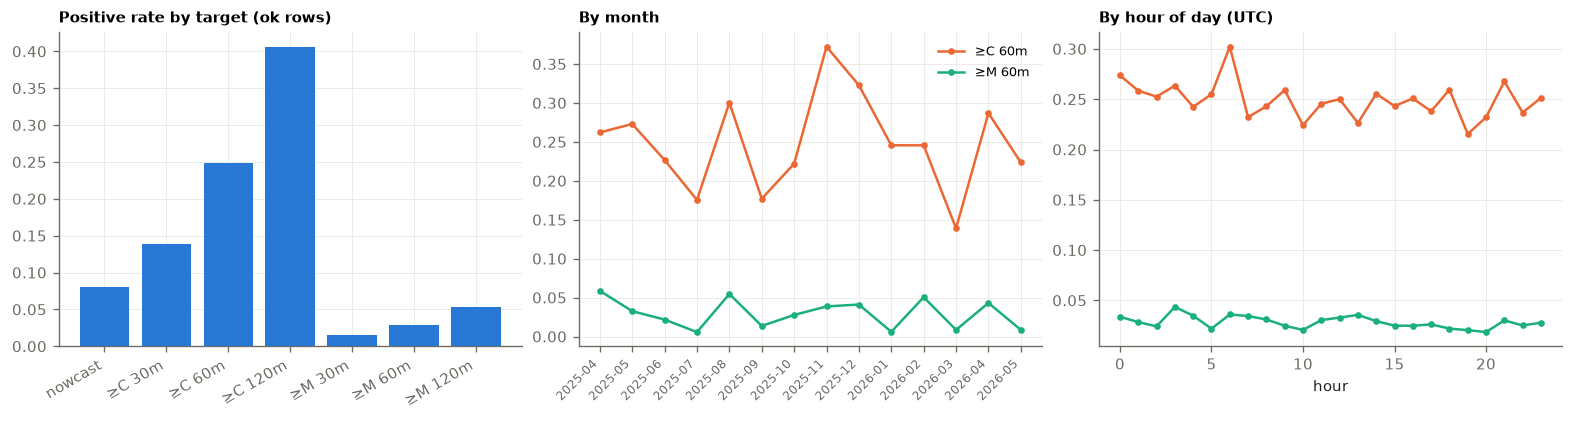

{'rates': {'nowcast': 0.08,
  '≥C 30m': 0.1386,
  '≥C 60m': 0.249,
  '≥C 120m': 0.4055,
  '≥M 30m': 0.0151,
  '≥M 60m': 0.0284,
  '≥M 120m': 0.0527},
 'month_c60_range': [0.13901670621432693, 0.3723818909872235],
 'month_m60_range': [0.005798688852020682, 0.05879327295574553],
 'hour_c60_range': [0.21553497942386832, 0.30226008589734565]}

In [9]:
br = eda.base_rates(d); display(Image(br['fig'])); {k: v for k, v in br.items() if k != 'fig'}

**Takeaway: label base rates.** Positive rates on ok rows: nowcast 8.0 %; ≥C within 30 / 60 / 120 min 13.9 / 24.9 / 40.6 %; ≥M 1.5 / 2.8 / 5.3 %. Rates swing strongly by month (≥C 60 min: 14–37 %; ≥M 60 min: 0.6–5.9 %, a tenfold range). Variation by hour of day (≥C 60 min: 22–30 %) has no physical cause and probably reflects when SoLEXS was observing (coverage patterns such as the 17th-of-month gap). *For modelling:* M forecasts are rare-event problems, so TSS and HSS rather than accuracy; monthly swings again argue for chronological validation and confidence intervals.

## 9. HEL1OS (hard X-rays), overlapping data only

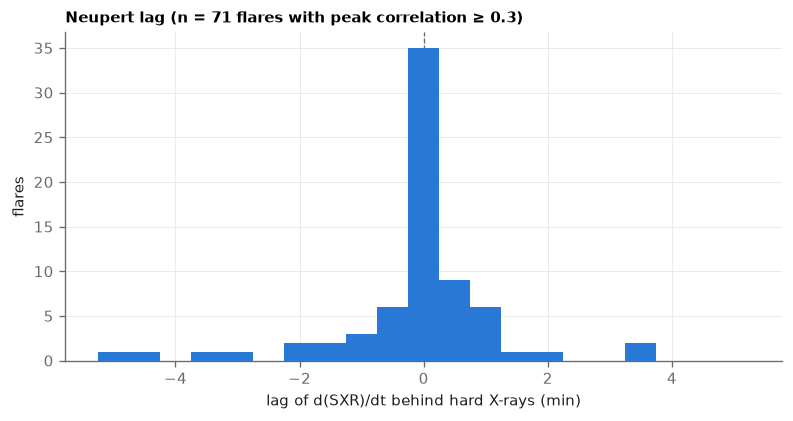

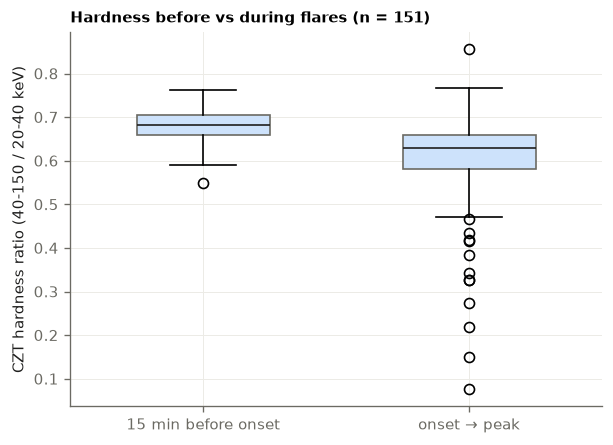

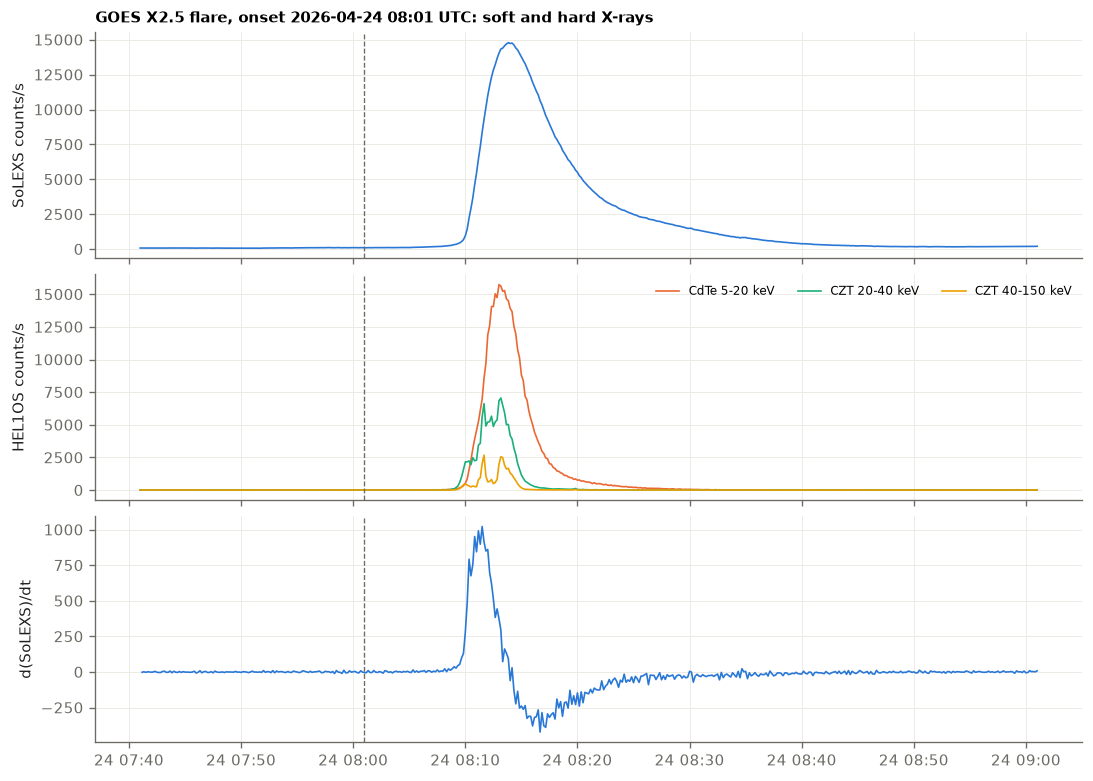

{'available': True,
 'per_period': {'tune': {'overlap_days': 13,
   'overlap_hours': 215.6,
   'goes_in_hel1os_time': {'C': 75, 'M': 27, 'X': 0}},
  'val': {'overlap_days': 8,
   'overlap_hours': 143.5,
   'goes_in_hel1os_time': {'C': 70, 'M': 14, 'X': 2}}},
 'neupert': {'n': 71, 'median_lag_s': 0.0, 'iqr_s': [-10.0, 20.0]},
 'hardness': {'n': 151,
  'median_before': 0.6831296682357788,
  'median_during': 0.6281652450561523,
  'share_harder_during': 0.17218543046357615},
 'example': 'X2.5 2026-04-24 08:01:00+00:00'}

In [10]:
chan = eda.load_hel1os_channels()
if chan is not None: eda.check_no_test(chan)
hx = eda.hel1os_eda(chan, m, ev, g, d)
for k in ('fig_neupert', 'fig_hardness', 'fig_example'):
    if k in hx: display(Image(hx[k]))
{k: v for k, v in hx.items() if not k.startswith('fig')}

**Takeaway: HEL1OS.** Overlap with usable SoLEXS rows: **tune 13 days / 215.6 h** with GOES flares starting inside HEL1OS time C 75, M 27, X 0; **val 8 days / 143.5 h** with C 70, M 14, X 2 (days = days with any HEL1OS-available rows). The **Neupert lag** (cross-correlation of hard X-rays with d(SoLEXS)/dt, 71 flares with a clear correlation ≥ 0.3) has a median of **0 s** (IQR −10 to +20 s): hard X-rays and the soft X-ray rise rate peak together, as the Neupert effect predicts. This is also a strong check that the two instruments' timestamps are aligned. The CZT hardness ratio (40–150 / 20–40 keV) *falls* during flares (median 0.68 before → 0.63 from onset to peak; harder in only 17 % of 151 flares), because quiet-time CZT counts are dominated by a flat background and flare photons concentrate at 20–40 keV. *For modelling:* HEL1OS covers only about 2 % of tune+val time and validation has only 16 M/X flares inside it, so any soft vs hard comparison for M forecasts will be underpowered.

In [11]:
summary = dict(coverage=cov, long_term=lt, activity=at, profiles=se, stats=fs, detector=dg, features=fe,
               base_rates=br, hel1os=hx)
json.dump(summary, open('reports/eda_numbers.json', 'w', newline='\n'), indent=2, default=str); print('saved reports/eda_numbers.json')

saved reports/eda_numbers.json
